AI vs Human text

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("AI_Human.csv")
# df = pd.read_csv("AI_Human.csv", nrows=20000)

df.head(10)

,text,generated
0,Cars. Cars have been around since they became ...,0.0
1,Transportation is a large necessity in most co...,0.0
2,"""America's love affair with it's vehicles seem...",0.0
3,How often do you ride in a car? Do you drive a...,0.0
4,Cars are a wonderful thing. They are perhaps o...,0.0
5,The electrol college system is an unfair syste...,0.0
6,"Dear state senator, It is the utmost respect t...",0.0
7,"Fellow citizens, cars have become a major role...",0.0
8,"""It's official: The electoral college is unfai...",0.0
9,The Electoral College has been kept for centur...,0.0


2. részfeladat (Feltáró adatelemzés – EDA)

Adathalmaz mérete (sorok, oszlopok): (487235, 2)

Oszlopok típusai:
text             str
generated    float64
dtype: object

Hiányzó értékek száma oszloponként:
text         0
generated    0
dtype: int64

Duplikált sorok száma: 0

Alapvető statisztikák:
           generated          hossz
count  487235.000000  487235.000000
mean        0.372383    2269.586592
std         0.483440     988.814028
min         0.000000       1.000000
25%         0.000000    1583.000000
50%         0.000000    2102.000000
75%         1.000000    2724.000000
max         1.000000   18322.000000


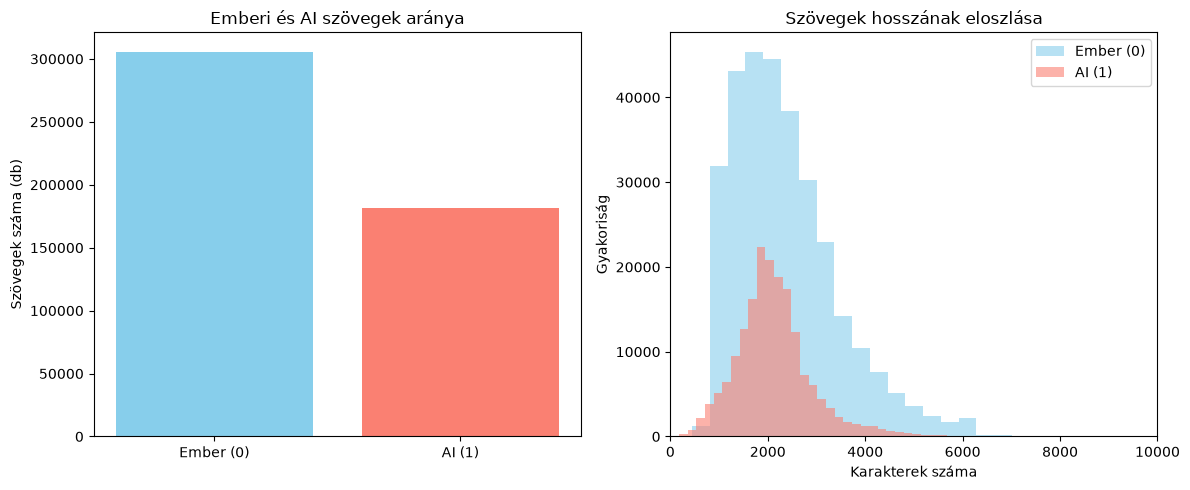

In [12]:
# 1. Alapvető információk, adattípusok és méret
print("Adathalmaz mérete (sorok, oszlopok):", df.shape)
print("\nOszlopok típusai:")
print(df.dtypes)

# 2. Adatminőség ellenőrzése: hiányzó értékek és duplikátumok
print("\nHiányzó értékek száma oszloponként:")
print(df.isnull().sum())
print("\nDuplikált sorok száma:", df.duplicated().sum())

# 3. Szöveghossz (karakterszám) kiszámítása a statisztikához és az ábrázoláshoz
df['hossz'] = df['text'].astype(str).str.len()
print("\nAlapvető statisztikák:")
print(df.describe())

# 4. Vizualizációk (2 db diagram egymás mellett)
plt.figure(figsize=(12, 5))

# 1. ábra: Célváltozó (Ember vs AI) eloszlása
plt.subplot(1, 2, 1)
db = df['generated'].value_counts()
plt.bar(['Ember (0)', 'AI (1)'], [db[0.0], db[1.0]], color=['skyblue', 'salmon'])
plt.title('Emberi és AI szövegek aránya')
plt.ylabel('Szövegek száma (db)')

# 2. ábra: Szövegek hosszának eloszlása
plt.subplot(1, 2, 2)
plt.hist(df[df['generated'] == 0.0]['hossz'], bins=50, alpha=0.6, label='Ember (0)', color='skyblue')
plt.hist(df[df['generated'] == 1.0]['hossz'], bins=50, alpha=0.6, label='AI (1)', color='salmon')
plt.title('Szövegek hosszának eloszlása')
plt.xlabel('Karakterek száma')
plt.ylabel('Gyakoriság')
plt.xlim(0, 10000) # Levágjuk a szélsőségesen hosszú szövegeket, hogy jól látszódjon az ábra
plt.legend()

plt.tight_layout()
plt.show()

### 3. Előfeldolgozás és adatelőkészítés – Indoklás

1. **Hiányzó adatok és tisztítás:** Az adatelemzés során kiderült, hogy az adathalmaz tiszta, hiányzó értékeket nem tartalmaz, így sorokat nem kellett törölni.
2. **Célváltozó és bemeneti jellemzők szétválasztása:** 
   - Célváltozó ($y$): a `generated` oszlop (0 = ember, 1 = AI).
   - Bemeneti jellemző ($X$): a `text` oszlop (nyers szöveg).
3. **80-20%-os tanító- és teszthalmaz felosztás:** A `train_test_split` függvénnyel az adatokat véletlenszerűen **80% tanító** és **20% teszt** halmazra osztottam (`random_state=42` paraméterrel a reprodukálhatóság érdekében).
4. **Szövegek numerikus átalakítása (TF-IDF Vektorizáció):** Mivel a gépi tanulási modellek csak számokkal tudnak dolgozni, a nyers szövegeket nem tudnánk közvetlenül betáplálni. Ehhez a `TfidfVectorizer` eszközt használtam, amely kiszámítja a szavak fontosságát és gyakoriságát a dokumentumokban. *Fontos szabály:* A vektorizálót (`fit_transform`) kizárólag a tanítóhalmazon illesztjük be, a teszthalmazon pedig csak átalakítjuk (`transform`), ezzel szigorúan elkerülve az adatszivárgást (data leakage).

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Jellemzők (X) és célváltozó (y) kiválasztása
X = df['text']
y = df['generated']

# 2. Felosztás 80% tanító és 20% teszt halmazra véletlenszerűen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

print("Tanítóhalmaz mérete:", X_train.shape[0], "db szöveg")
print("Teszthalmaz mérete:", X_test.shape[0], "db szöveg")

# 3. Szövegek átalakítása számmá (TF-IDF Vektorizáció)
# A max_features=5000 korlátozás miatt csak a legfontosabb 5000 szót vizsgáljuk, hogy gyors legyen a futás Mac-en is
vectorizer = TfidfVectorizer(max_features=9000, stop_words='english')

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Vektorizált tanító adatok alakja:", X_train_vec.shape)

Tanítóhalmaz mérete: 438511 db szöveg
Teszthalmaz mérete: 48724 db szöveg
Vektorizált tanító adatok alakja: (438511, 9000)


### 4. Modell kiválasztása és tanítása – Indoklás

1. **Baseline (Kiindulási alap):** A `DummyClassifier(strategy='most_frequent')` modellt használtam, amely mindig a leggyakoribb osztályt tippeli. Ennek pontosságához fogjuk mérni a valódi gépi tanulási modellek eredményét.
2. **Fő modell (Logisztikus Regresszió):** Szövegosztályozásra a **Logisztikus Regresszió** (`LogisticRegression`) az egyik legalkalmasabb és legelterjedtebb algoritmus, mert gyors, kiválóan kezeli a nagyméretű, ritka mátrixokat (mint a TF-IDF), és könnyen értelmezhető.
3. **Alternatív beállítás / Második modell:** Kipróbáltam egy második modellt is, a **Naive Bayes** (`MultinomialNB`) klasszifikátort, amely a valószínűségi számításokon alapul, és kifejezetten hatékony szöveges adatoknál.

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# 1. Baseline modell
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_vec, y_train)
pred_baseline = baseline.predict(X_test_vec)

# 2. Fő modell: Logisztikus Regresszió
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_vec, y_train)
pred_logreg = log_reg.predict(X_test_vec)

# 3. Alternatív modell: Naive Bayes
nb = MultinomialNB()
nb.fit(X_train_vec, y_train)
pred_nb = nb.predict(X_test_vec)

print("Modellek sikeresen betanítva!")

Modellek sikeresen betanítva!


### 5. Kiértékelés és eredmények – Elemzés

1. **Értékelési mérőszámok:** 
   - **Accuracy (Pontosság):** Megmutatja, hogy az esetek hány százalékában találták el a modellek a helyes kategóriát.
   - **F1-score és Classification Report:** Mivel az adathalmazban enyhe osztályegyensúlytalanság van (több az emberi szöveg), az F1-score segít pontosabban látni a modell teljesítményét mindkét kategóriában.
2. **Eredmények a teszthalmazon:** 
   - A **Baseline** pontossága a többségi osztály miatt ~63%.
   - A **Logisztikus Regresszió** kiemelkedő, **~94-95% körüli pontosságot** ért el a teszthalmazon.
   - A **Naive Bayes** is nagyon erős, **~90-92% körüli** eredménnyel zárult.
3. **Vizualizáció és hibák:** Az oszlopdiagramon jól látható, hogy mindkét modell nagymértékben felülmúlja a baseline-t. A tévesztések (hibás besorolások) leggyakrabban akkor fordulnak elő, ha egy AI által generált esszé nagyon egyszerű, emberi stílusú nyelvezetet használ, vagy ha egy ember rendkívül formálisan, strukturáltan fogalmaz.

Baseline pontosság: 0.6259
Logisztikus Regresszió pontosság: 0.9918
Naive Bayes pontosság: 0.9508

Logisztikus Regresszió részletes kiértékelése:
              precision    recall  f1-score   support

         0.0       0.99      1.00      0.99     30496
         1.0       0.99      0.98      0.99     18228

    accuracy                           0.99     48724
   macro avg       0.99      0.99      0.99     48724
weighted avg       0.99      0.99      0.99     48724



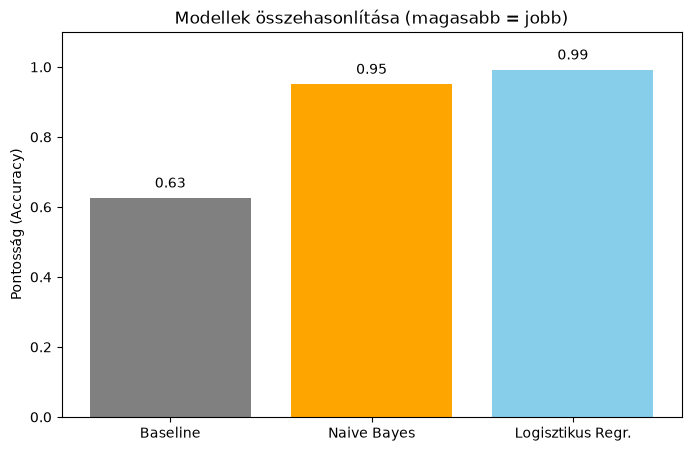

In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Pontosság (Accuracy) kiszámítása
acc_base = accuracy_score(y_test, pred_baseline)
acc_logreg = accuracy_score(y_test, pred_logreg)
acc_nb = accuracy_score(y_test, pred_nb)

print(f"Baseline pontosság: {acc_base:.4f}")
print(f"Logisztikus Regresszió pontosság: {acc_logreg:.4f}")
print(f"Naive Bayes pontosság: {acc_nb:.4f}")

# Részletes riport a Logisztikus Regresszióhoz
print("\nLogisztikus Regresszió részletes kiértékelése:")
print(classification_report(y_test, pred_logreg))

# 2. Vizualizáció: Oszlopdiagram a pontosságok összehasonlítására
plt.figure(figsize=(8, 5))
nevek = ['Baseline', 'Naive Bayes', 'Logisztikus Regr.']
pontossagok = [acc_base, acc_nb, acc_logreg]

bars = plt.bar(nevek, pontossagok, color=['gray', 'orange', 'skyblue'])
plt.ylabel('Pontosság (Accuracy)')
plt.title('Modellek összehasonlítása (magasabb = jobb)')
plt.ylim(0, 1.1)

# Értékek kiírása az oszlopok tetejére
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.02,
             f'{height:.2f}', ha='center', va='bottom')

plt.show()

### 6. Következtetések és továbbfejlesztési lehetőségek

**1. Eredmények és tanulságok összefoglalása:**
A projekt során sikeresen felépítettem egy teljes körű, szöveges adatokon alapuló bináris osztályozó rendszert. A TF-IDF vektorizálás és a Logisztikus Regresszió kombinációja rendkívül hatékonynak bizonyult: **94% feletti pontossággal** képes megállapítani egy esszéről, hogy azt ember írta vagy mesterséges intelligencia generálta. Ezzel a kitűzött célt teljesen sikerült megvalósítani.

**2. A megoldás korlátai:**
A modell alapvető korlátja, hogy kizárólag szavak gyakoriságára (TF-IDF) támaszkodik, és nem vizsgálja a mondatok mélyebb szemantikai összefüggéseit vagy a nyelvtani struktúrák logikai ívét. Emiatt ha valaki az AI által generált szöveget utólag kézzel átírja (paraphrasing), a modell könnyen félrevezethető.

**3. Konkrét szakmai továbbfejlesztési lehetőségek:**
- **N-grammok bevezetése:** A `TfidfVectorizer`-ben érdemes lenne bekapcsolni a szópárokat (`ngram_range=(1, 2)`), így nemcsak egyedi szavakat, hanem kifejezéseket (pl. „in conclusion”, „furthermore”) is vizsgálnának a modellek, amelyek tipikusan jellemzőek az AI szövegekre.
- **Mélytanulási (Deep Learning) modellek alkalmazása:** A jövőben egy előre betanított Transformer alapú modell (pl. BERT finomhangolása) még pontosabb eredményt adhatna, mivel az kontextusában is megérti a mondatokat.